In [1]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data=pd.read_csv('/content/Day-08_Soil Nutrients.csv')

In [5]:
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [6]:
data.tail()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
19377,19378,NaN,7578226840,21,NaN,not verified,active,NaN,NaN,NaN,NaN,NaN
19378,19379,NaN,6079236179,53,NaN,not verified,active,NaN,NaN,NaN,NaN,NaN
19379,19380,NaN,2565539685,10,NaN,verified,under review,NaN,NaN,NaN,NaN,NaN
19380,19381,NaN,2969178540,24,NaN,not verified,active,NaN,NaN,NaN,NaN,NaN
19381,19382,NaN,8132759688,13,NaN,not verified,active,NaN,NaN,NaN,NaN,NaN


In [7]:
data.shape

(19382, 12)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [9]:
data.isnull().sum()

,0
#,0
claim_status,298
video_id,0
video_duration_sec,0
video_transcription_text,298
verified_status,0
author_ban_status,0
video_view_count,298
video_like_count,298
video_share_count,298


In [10]:
data.min(numeric_only=True)

,0
#,1.000000e+00
video_id,1.234959e+09
video_duration_sec,5.000000e+00
video_view_count,2.000000e+01
video_like_count,0.000000e+00
video_share_count,0.000000e+00
video_download_count,0.000000e+00
video_comment_count,0.000000e+00


In [11]:
data.max(numeric_only=True)

,0
#,1.938200e+04
video_id,9.999873e+09
video_duration_sec,6.000000e+01
video_view_count,9.998170e+05
video_like_count,6.578300e+05
video_share_count,2.561300e+05
video_download_count,1.499400e+04
video_comment_count,9.599000e+03


In [12]:
data['video_share_count'].unique()

array([  241., 19034.,  2858., ...,  1270.,  1051.,    nan], shape=(9232,))

In [14]:
# Print available columns to find the correct column name
list(data.columns)

['#',
 'claim_status',
 'video_id',
 'video_duration_sec',
 'video_transcription_text',
 'verified_status',
 'author_ban_status',
 'video_view_count',
 'video_like_count',
 'video_share_count',
 'video_download_count',
 'video_comment_count']

In [15]:
data['video_comment_count'].unique()

array([   0.,  684.,  329., ..., 1006., 3372.,   nan], shape=(2425,))

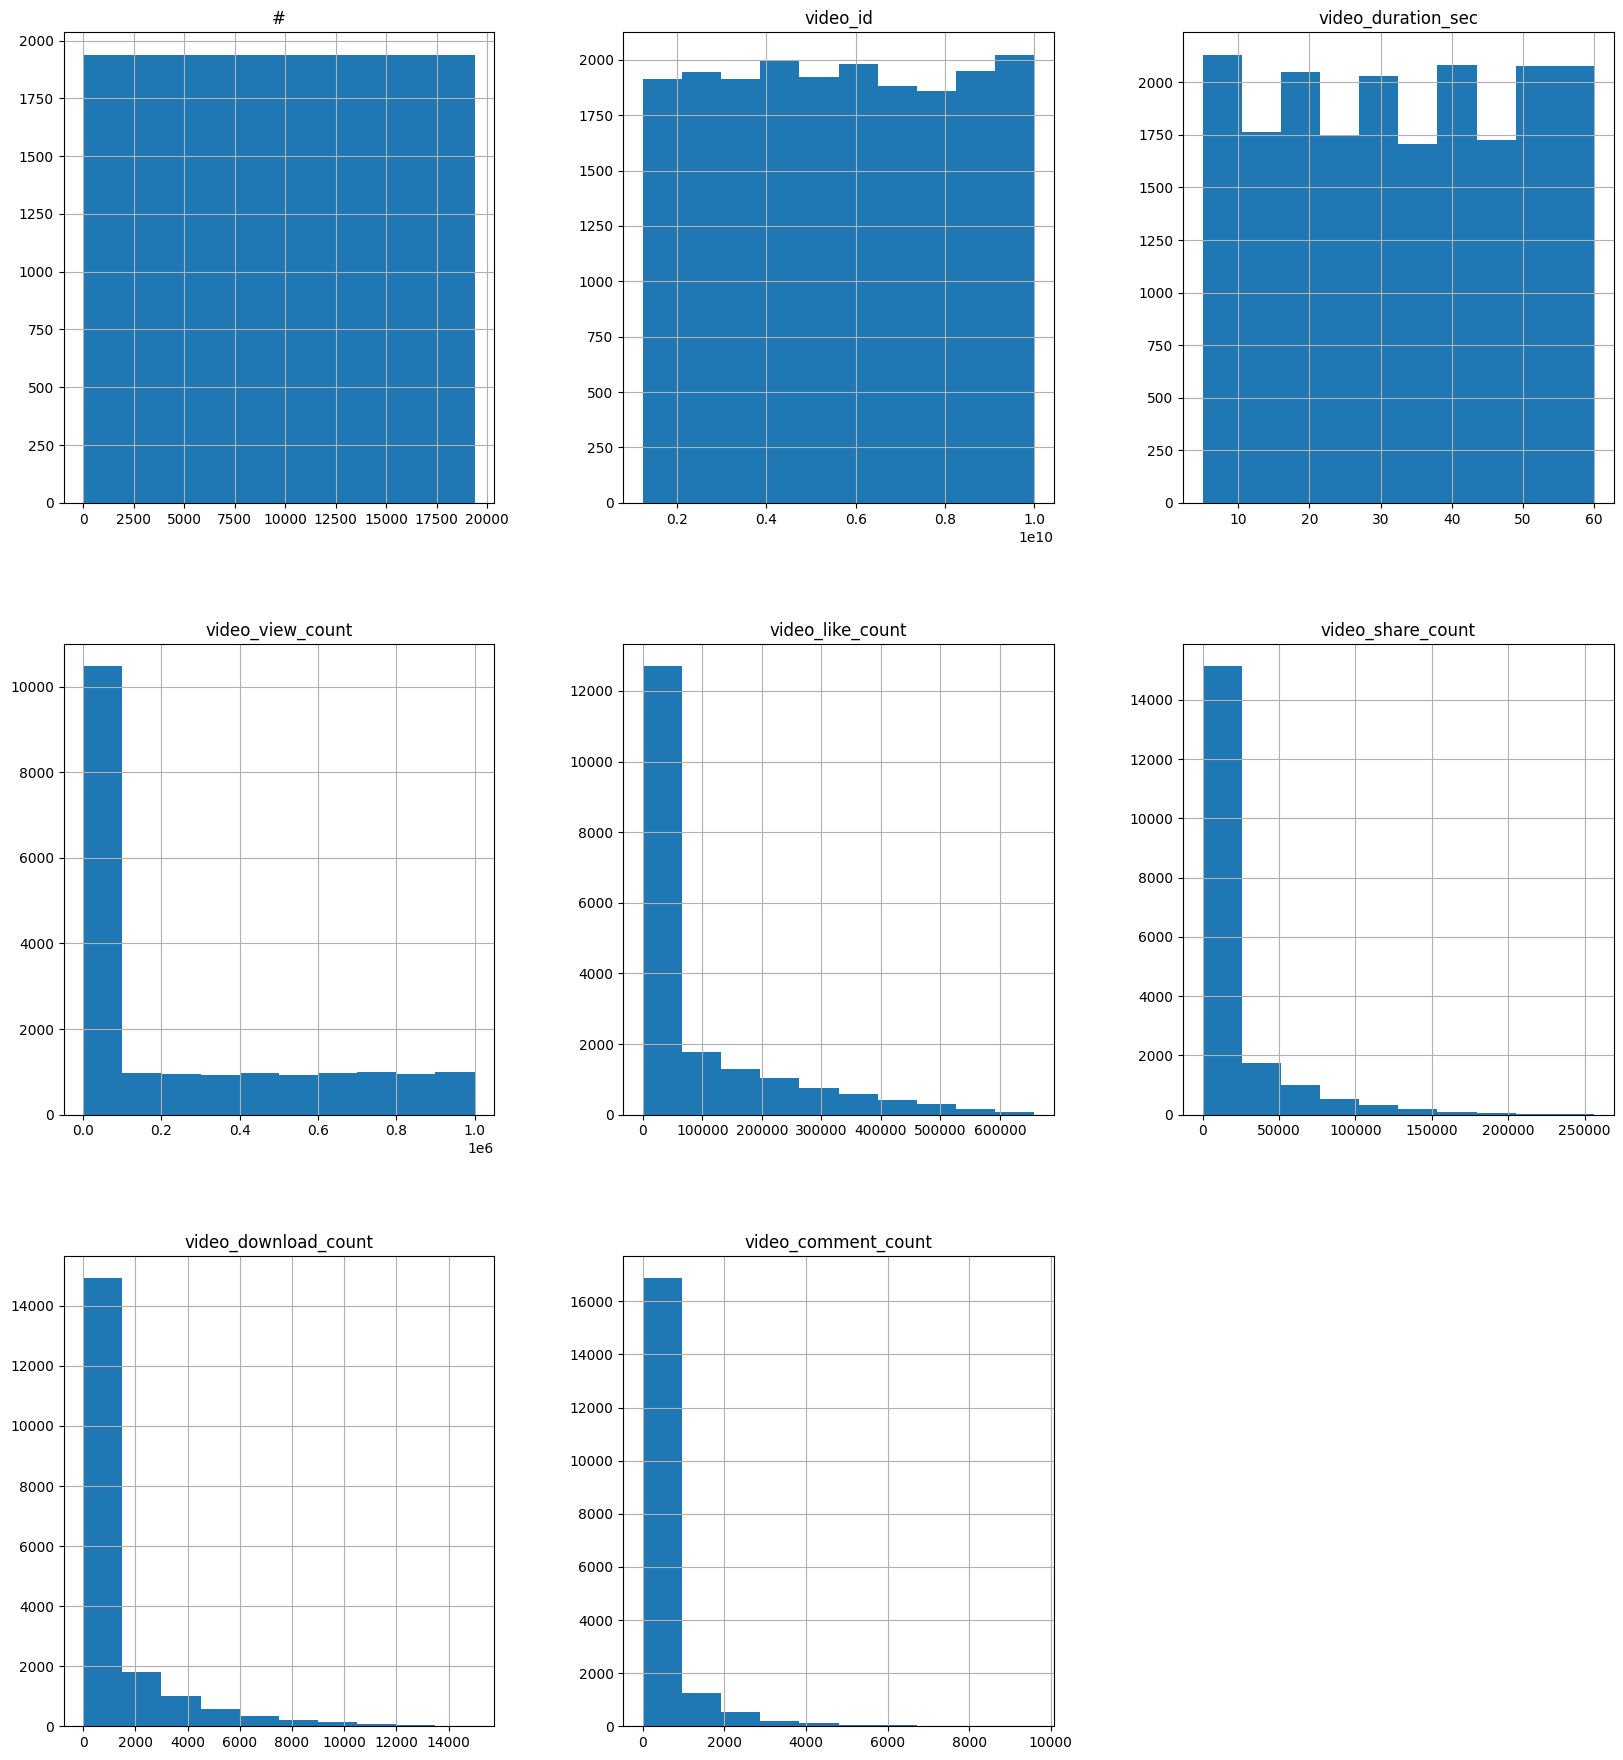

In [16]:
data.hist(figsize=(20, 22))
plt.show()

In [17]:
plt.show()

<Axes: >

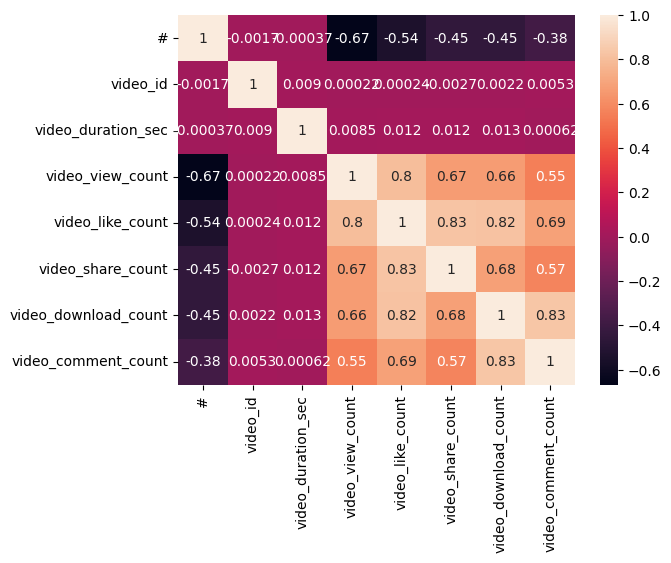

In [18]:
sns.heatmap(data.corr(numeric_only=True), annot=True)

In [19]:
c = data.corr(numeric_only=True).abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(ascending=False).head(15))

video_download_count  video_comment_count     0.832464
video_like_count      video_share_count       0.825789
                      video_download_count    0.823554
video_view_count      video_like_count        0.804322
video_like_count      video_comment_count     0.687185
video_share_count     video_download_count    0.679910
#                     video_view_count        0.668047
video_view_count      video_share_count       0.665635
                      video_download_count    0.664222
video_share_count     video_comment_count     0.574632
video_view_count      video_comment_count     0.554172
#                     video_like_count        0.540852
                      video_share_count       0.451713
                      video_download_count    0.447729
                      video_comment_count     0.377445
dtype: float64


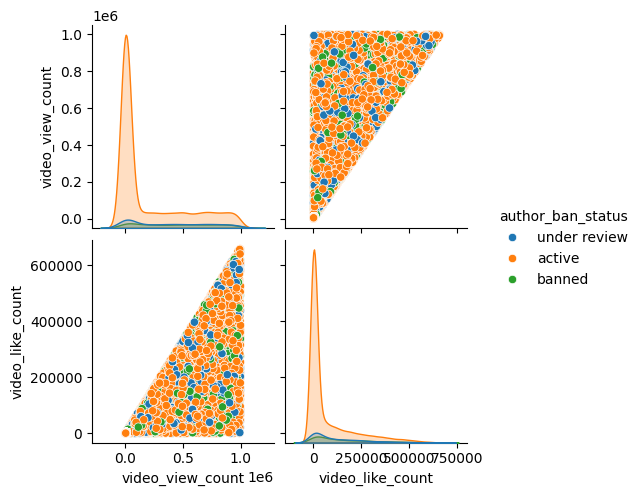

In [21]:
# Using existing columns from the video dataset
sns.pairplot(data[['video_view_count', 'video_like_count', 'author_ban_status']].dropna(), hue='author_ban_status')
plt.show()

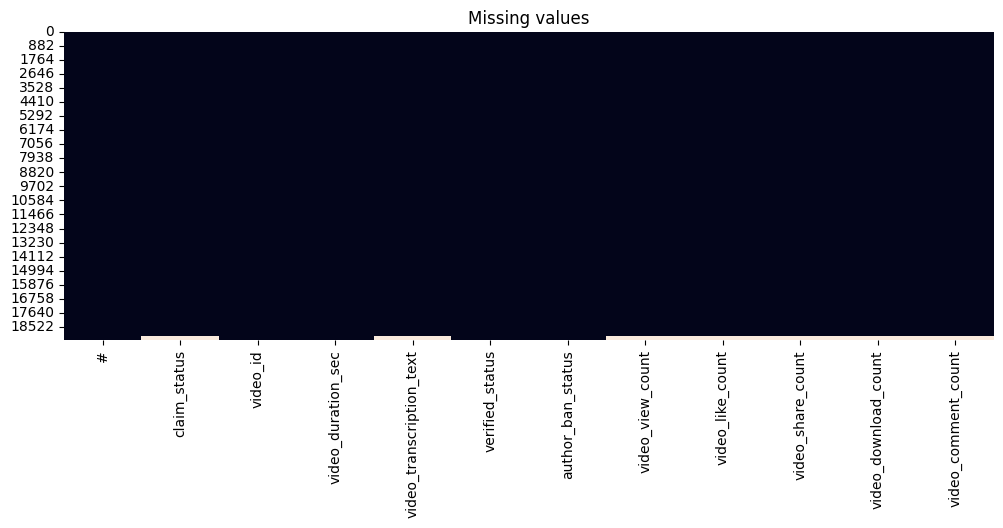

In [22]:
plt.figure(figsize=(12,4))
sns.heatmap(data.isna(), cbar=False)
plt.title("Missing values")
plt.show()

/tmp/ipykernel_906/256980334.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='author_ban_status', y='video_like_count', data=data, palette='viridis', errorbar=None)


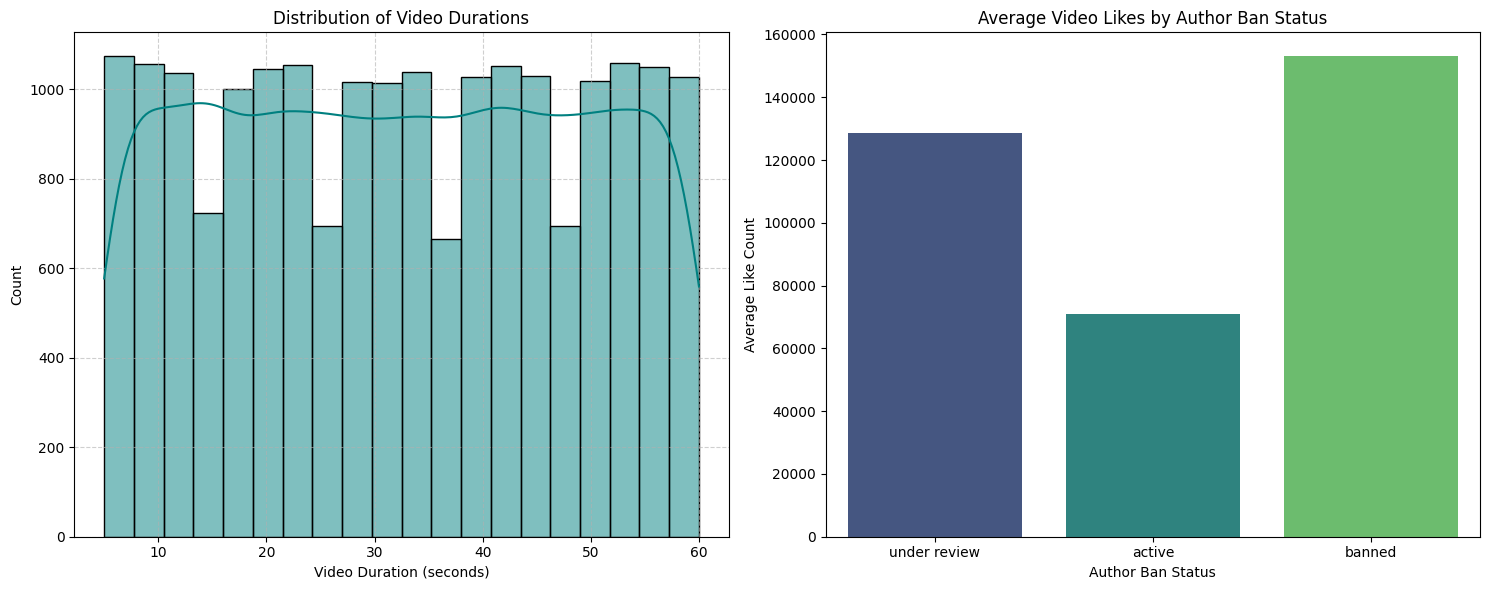

In [24]:
plt.figure(figsize=(15, 6))

# Subplot 1: Distribution of video durations
plt.subplot(1, 2, 1)
sns.histplot(data=data, x='video_duration_sec', bins=20, color='teal', kde=True)
plt.title('Distribution of Video Durations')
plt.xlabel('Video Duration (seconds)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Average video likes by author ban status
plt.subplot(1, 2, 2)
sns.barplot(x='author_ban_status', y='video_like_count', data=data, palette='viridis', errorbar=None)
plt.title('Average Video Likes by Author Ban Status')
plt.xlabel('Author Ban Status')
plt.ylabel('Average Like Count')

plt.tight_layout()
plt.show()

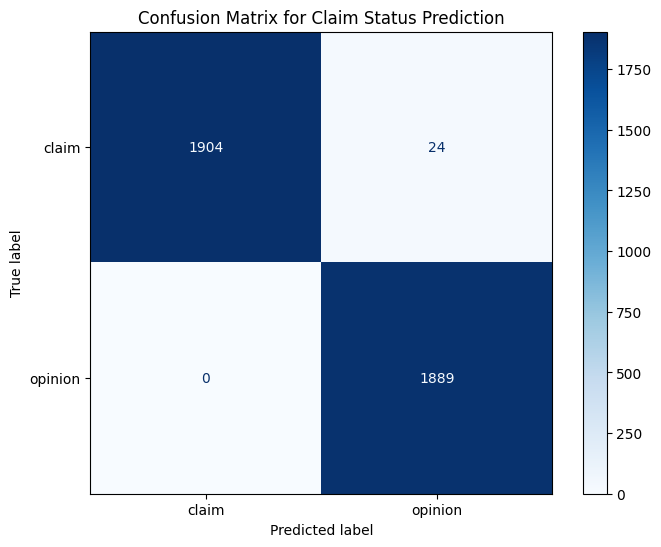

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model_df = data[['claim_status', 'video_view_count', 'video_like_count']].dropna()

X = model_df[['video_view_count', 'video_like_count']]
y = model_df['claim_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', ax=plt.gca())
plt.title('Confusion Matrix for Claim Status Prediction')
plt.show()

In [27]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)
print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

       claim       1.00      0.99      0.99      1928
     opinion       0.99      1.00      0.99      1889

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



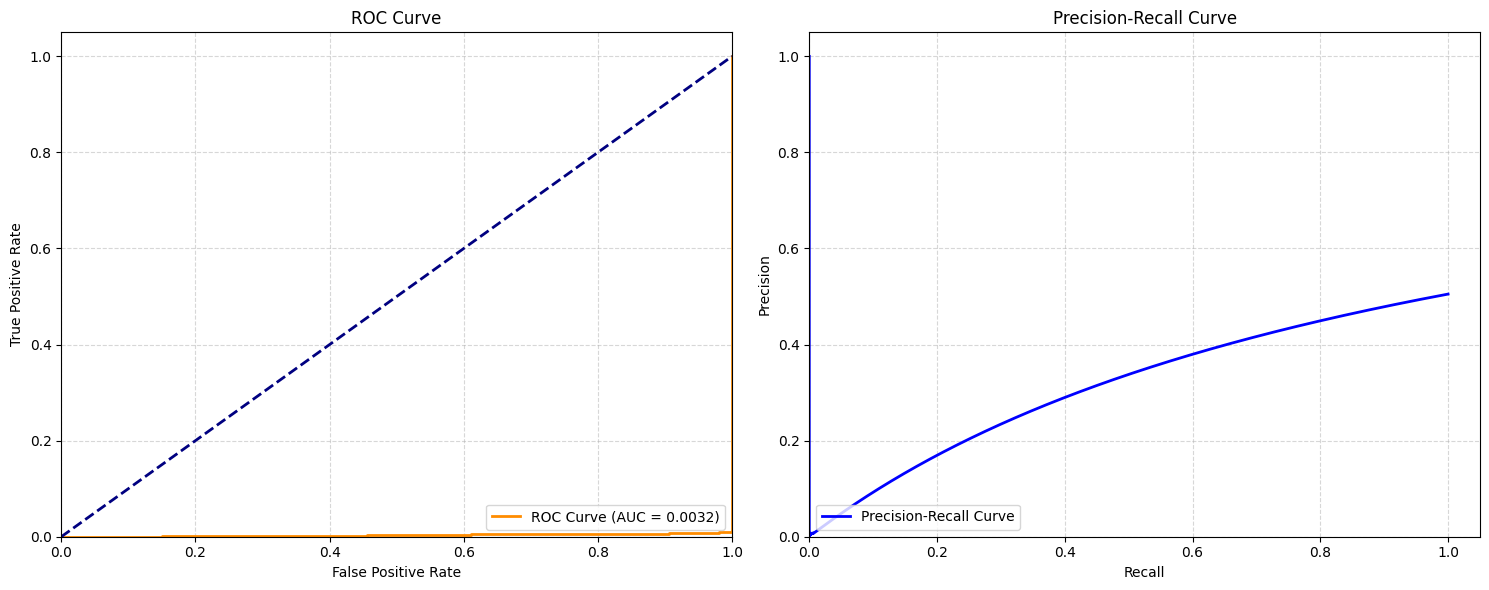

In [29]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve

y_test_binary = (y_test == 'claim').astype(int)
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test_binary, y_prob)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_test_binary, y_prob)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim([0.0, 1.05])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower left")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_906/4266180837.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefficients, y=features, palette='mako')


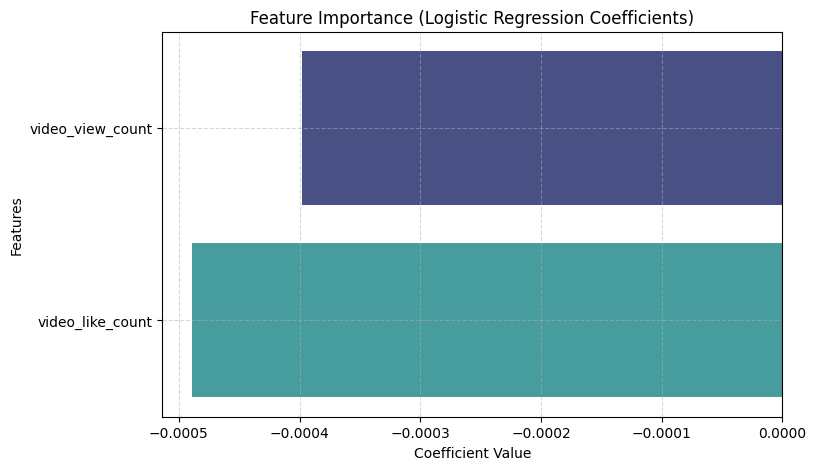

In [30]:
# Calculate feature importance (coefficients in Logistic Regression)
import numpy as np

coefficients = model.coef_[0]
features = X.columns

# Plot Feature Importance
plt.figure(figsize=(8, 5))
sns.barplot(x=coefficients, y=features, palette='mako')
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

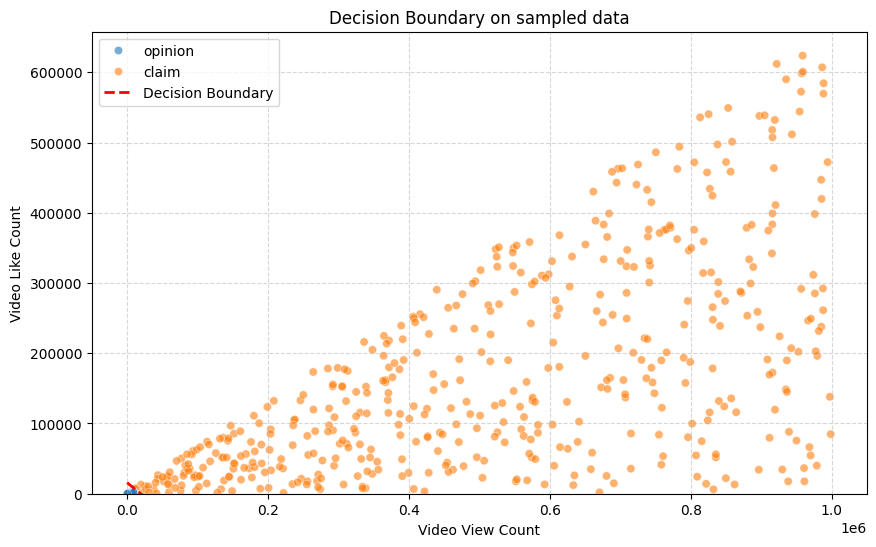

In [32]:
# Plotting a simplified decision boundary
plt.figure(figsize=(10, 6))
sns.scatterplot(data=model_df.sample(1000, random_state=42), x='video_view_count', y='video_like_count', hue='claim_status', alpha=0.6)

# Retrieve model parameters
b = model.intercept_[0]
w1, w2 = model.coef_[0]

# Calculate the decision boundary line: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b) / w2
x_values = np.linspace(model_df['video_view_count'].min(), model_df['video_view_count'].max(), 100)
y_values = -(w1 * x_values + b) / w2

plt.plot(x_values, y_values, color='red', linestyle='--', linewidth=2, label='Decision Boundary')
plt.title('Decision Boundary on sampled data')
plt.xlabel('Video View Count')
plt.ylabel('Video Like Count')
plt.ylim(model_df['video_like_count'].min(), model_df['video_like_count'].max())
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()